In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xtrack as xt
import xcoll as xc
import xpart as xp
import xobjects as xo

In [2]:
def remove_offmom_bpms_apers(line, exn=3.5e-6, nrj=21, pmass=0.938, bucket_height=3e-3, n_buckets=2):
    "Remove apertures of off-momentum BPMs which give flanges as bottlenecks"
    tt = line.get_table()
    tw = line.twiss()
    mask_disp = 5*np.sqrt(tw.betx*exn*pmass/nrj)+n_buckets*bucket_height*tw.dx > 0.025
    mask_bpm = ['bp' in name for name in tt.name]
    mask_aper = np.array(['aper' in name for name in tt.name])
    offmom_bpms = tt.name[mask_disp & mask_bpm & ~mask_aper]
    aper_to_remove = [f'{name}{suffix}' for name in offmom_bpms for suffix in ('.a_aper', '.b_aper')]
    line.remove(aper_to_remove)

def install_tidp(line, block_mvt=29e-3):
    tidp_ap_tot = 147e-3
    line.discard_tracker()
    tidp = xc.EverestCollimator(length=4.3, material=xc.materials.CarbonFibreCarbon, jaw_L= tidp_ap_tot/2 + block_mvt, jaw_R = -tidp_ap_tot/2 + block_mvt)
    line.collimators.install(names=['tidp.11434'], elements=[tidp])
    return tidp

def install_tcsm(line, gap=5):
    tcsm = xc.EverestCollimator(length=1.83, gap=gap, material=xc.materials.CarbonFibreCarbon) # length is 1.83
    line.collimators.install(names=['tcsm.51932'], elements=[tcsm])
    return tcsm

In [3]:
num_particles = 1000
num_turns = 3000
plane = 'H'
amplitude_adt = 0.095
start_at_turn= 100
nemitt_x = 2e-6
nemitt_y = 2e-6
time_per_turn = 2.305894738364788e-05
total_crab_voltage = 1e6
ramping_turns = 100
use_individual_kicks = True
xcoll_version = xc.__version__

In [4]:
line = xt.Line.from_json('../../sps_with_aperture_inj_q20_beam_sagitta4.json')

env = line.env
tt = line.get_table()

remove_offmom_bpms_apers(line, exn=3.5e-6, nrj=21, pmass=0.938, bucket_height=3e-3, n_buckets=2)
tidp = install_tidp(line, block_mvt=29e-3)
tcsm = install_tcsm(line)
# monitor = xt.ParticlesMonitor(num_particles=num_particles, start_at_turn=0, stop_at_turn=num_turns)
# env.elements['monitor_tcsm'] = monitor
# line.insert([env.place('monitor_tcsm', at='tcsm.51932@end')])
# line['cc_voltage_ramping'] =  total_crab_voltage / (ramping_turns * time_per_turn) * line.ref['t_turn_s']
# line['acfcah.61738'].crab_voltage = 'cc_voltage_ramping'
# line['acfcah.61739'].crab_voltage = 'cc_voltage_ramping'

Loading line from dict:   0%|          | 0/36381 [00:00<?, ?it/s]

/Users/lisepauwels/Xsuite/xtrack/xtrack/beam_elements/elements.py:793: FutureWarning: `lag` (in degrees) is deprecated and will be removed in a future version. Please use `phase` (in radians) instead. If you see this warning while loading a saved line from a previous version of Xsuite, please regenerate the line with the current version to use phase instead of lag. Note that if both `lag` and `phase` are set, the effect is the sum of the two,  with `lag` converted to radians.  This deprecation is part of the interface cleanup in view of the 1.0 release.
  self.lag = lag
/Users/lisepauwels/Xsuite/xtrack/xtrack/beam_elements/elements.py:3783: FutureWarning: `pn` (in degrees) is deprecated and will be removed in a future version. Please use `phase_n` (in radians) instead. Note that if both `pn` and `phase_n` are set, the effect is the sum of the two with `pn` converted to radians.
  self._warn_if_deprecated_phase_is_nonzero(pn, 'pn', 'phase_n')
/Users/lisepauwels/Xsuite/xtrack/xtrack/beam

Done loading line from dict.           


/var/folders/b5/swvf1qzj6l36gcd1zzs4_g8h0000gn/T/ipykernel_20395/1801299270.py:16: FutureWarning: `Line.collimators` is deprecated and will be removed in a future version. Please use `Line.xcoll.collimators` instead.
  line.collimators.install(names=['tidp.11434'], elements=[tidp])


Slicing line:   0%|          | 0/32244 [00:00<?, ?it/s]

/var/folders/b5/swvf1qzj6l36gcd1zzs4_g8h0000gn/T/ipykernel_20395/1801299270.py:21: FutureWarning: `Line.collimators` is deprecated and will be removed in a future version. Please use `Line.xcoll.collimators` instead.
  line.collimators.install(names=['tcsm.51932'], elements=[tcsm])


Slicing line:   0%|          | 0/32242 [00:00<?, ?it/s]

In [5]:
adt = xc.BlowUp.install(line, name=f'adt_{plane}_blowup', at_s=line.get_s_position('adkcv.32171'), plane=plane, stop_at_turn=num_turns,
                        amplitude=amplitude_adt, use_individual_kicks=use_individual_kicks, start_at_turn=start_at_turn)

# impacts = xc.InteractionRecord.start(line=line)
tw = line.twiss()
line.collimators.assign_optics(twiss=tw, nemitt_x=nemitt_x, nemitt_y=nemitt_y)

/var/folders/b5/swvf1qzj6l36gcd1zzs4_g8h0000gn/T/ipykernel_20395/3699555499.py:1: FutureWarning: `Line.get_s_position` is deprecated and will be removed in a future version. Use `tt = line.get_table()` and then `tt.s` to get all s positions or `tt['s', 'myelem']` for one specific s position. This deprecation is part of the interface cleanup in view of the 1.0 release.
  adt = xc.BlowUp.install(line, name=f'adt_{plane}_blowup', at_s=line.get_s_position('adkcv.32171'), plane=plane, stop_at_turn=num_turns,
/Users/lisepauwels/Xsuite/xcoll/xcoll/beam_elements/blowup.py:69: FutureWarning: Warning: `at_s` is deprecated and will be removed in the future. Please use `at` instead.
  warn("Warning: `at_s` is deprecated and will be removed in "


Slicing line:   0%|          | 0/32242 [00:00<?, ?it/s]

/var/folders/b5/swvf1qzj6l36gcd1zzs4_g8h0000gn/T/ipykernel_20395/3699555499.py:6: FutureWarning: `Line.collimators` is deprecated and will be removed in a future version. Please use `Line.xcoll.collimators` instead.
  line.collimators.assign_optics(twiss=tw, nemitt_x=nemitt_x, nemitt_y=nemitt_y)


In [6]:
part = xp.generate_matched_gaussian_bunch(nemitt_x=nemitt_x,
                                          nemitt_y=nemitt_y,
                                          sigma_z=0.224, num_particles=num_particles, line=line)
part_init = part.copy()

*** Maximum RMS bunch length 0.2333663781336932m.
... distance to target bunch length: -2.2228e-01
... distance to target bunch length: 4.5424e-03
... distance to target bunch length: 4.3382e-03
... distance to target bunch length: -6.6565e-03
... distance to target bunch length: 2.0203e-03
... distance to target bunch length: -5.7185e-04
... distance to target bunch length: 1.0779e-04
... distance to target bunch length: 4.7891e-06
... distance to target bunch length: -2.0504e-09
... distance to target bunch length: 9.6490e-08
--> Bunch length: 0.22399999794961267
--> Emittance: 0.34347719148636374


In [7]:
# line.enable_time_dependent_vars=True
adt.calibrate_by_emittance(nemitt=nemitt_x, twiss=tw)

line.discard_tracker()
line.build_tracker(_context=xo.ContextCpu(omp_num_threads='auto'))
line.scattering.enable()
adt.activate()
line.track(part, num_turns=3000, with_progress=True, turn_by_turn_monitor=True)
adt.deactivate()
line.scattering.disable()
mon = line.record_last_track

Compiling ContextCpu kernels...


ld: warning: duplicate -rpath '/Users/lisepauwels/miniforge3/envs/xcoll/lib' ignored
ld: warning: duplicate -rpath '/Users/lisepauwels/miniforge3/envs/xcoll/lib' ignored


Done compiling ContextCpu kernels.
Compiling ContextCpu kernels...


/var/folders/b5/swvf1qzj6l36gcd1zzs4_g8h0000gn/T/ipykernel_20395/2768789653.py:6: FutureWarning: `Line.scattering` is deprecated and will be removed in a future version. Please use `Line.xcoll.scattering` instead.
  line.scattering.enable()
ld: warning: duplicate -rpath '/Users/lisepauwels/miniforge3/envs/xcoll/lib' ignored
ld: warning: duplicate -rpath '/Users/lisepauwels/miniforge3/envs/xcoll/lib' ignored


Done compiling ContextCpu kernels.


Tracking:   0%|          | 0/3000 [00:00<?, ?it/s]

/var/folders/b5/swvf1qzj6l36gcd1zzs4_g8h0000gn/T/ipykernel_20395/2768789653.py:10: FutureWarning: `Line.scattering` is deprecated and will be removed in a future version. Please use `Line.xcoll.scattering` instead.
  line.scattering.disable()


In [8]:
mon

ParticlesMonitor(start_at_turn=np.int64(0), stop_at_turn=np.int64(3000), part_id_start=np.int64(0), part_id_end=np.int64(1000), ebe_mode=np.int64(0), n_records=np.int64(3000000), n_repetitions=np.int64(1), repetition_period=np.int64(-1), flag_auto_to_numpy=np.int64(1), data=Particles(q0=0, mass0=0, p0c=[2.592e+10, 2.592e+10, 2.592e+10, ..., 0.000e+00,
                0.000e+00, 0.000e+00], shape=(3000000,), gamma0=[27.64334239, 27.64334239, 27.64334239, ...,  0.        ,
                 0.        ,  0.        ], shape=(3000000,), beta0=[0.99934547, 0.99934547, 0.99934547, ..., 0.        ,
                0.        , 0.        ], shape=(3000000,), s=[0., 0., 0., ..., 0., 0., 0.], shape=(3000000,), zeta=[-0.14692805, -0.17001814, -0.19172965, ...,  0.        ,
        0.        ,  0.        ], shape=(3000000,), x=[0.01484025, 0.01607143, 0.01606303, ..., 0.        , 0.        ,
       0.        ], shape=(3000000,), y=[ 0.00196939,  0.00150957, -0.00049121, ...,  0.        ,
        0.  

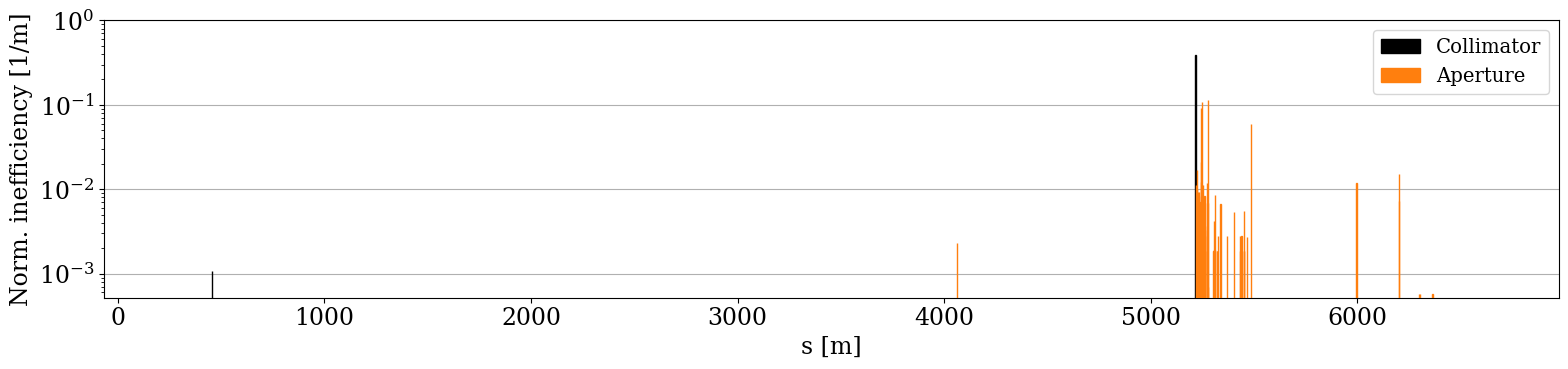

(<Figure size 1600x400 with 1 Axes>,
 <Axes: xlabel='s [m]', ylabel='Norm. inefficiency [1/m]'>)

In [9]:
ThisLM = xc.LossMap(line = line, line_is_reversed=False, part=part, interpolation=False)
ThisLM.plot()

In [10]:
np.max(ThisLM.aperture_losses['n']), ThisLM.aperture_losses['name'][np.argmax(ThisLM.aperture_losses['n'])], ThisLM.aperture_losses['s'][np.argmax(ThisLM.aperture_losses['n'])]

(np.float64(34.0), np.str_('vttm.52002.b_aper'), np.float64(5242.61145))

In [11]:
np.where(np.array(line.element_names) == 'vttm.52002.b_aper')

(array([24381]),)

In [12]:
pids = part.particle_id[part.at_element == 24381]
mon_idxs = [np.where(mon.particle_id[:,-1]==pid)[0] for pid in pids]

In [13]:
pids

array([136, 131, 435, 582, 232, 596,  13, 952, 884, 929, 795, 419, 374,
       312, 520, 625, 908, 431, 954, 660, 372, 172, 787, 742,  65, 967,
       491,  68, 322, 224, 309, 230, 254, 196])

In [14]:
part.x[np.where(part.particle_id == pids[0])[0]], part.y[np.where(part.particle_id == pids[0])[0]]

(array([-0.03017921]), array([0.02553875]))

In [15]:
env['vttm.52002.b_aper']

View of LimitEllipse(a=0.076, b=0.0208)

In [16]:
mon.particle_id[mon.at_element == 24381]

array([], dtype=int64)

In [17]:
np.nonzero(mon.at_turn[0])

(array([  1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,  13,
         14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,  26,
         27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,  39,
         40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,  52,
         53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,  65,
         66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,  78,
         79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,  91,
         92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103, 104,
        105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117,
        118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130,
        131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143,
        144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156,
        157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169,
        170, 171, 172, 173, 174, 175, 176, 177, 178

In [18]:
mon.particle_id[0]

array([0, 0, 0, ..., 0, 0, 0], shape=(3000,))

In [19]:
mon_idxs

[array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64)]

In [20]:
mon.x[502], mon.y[502]

(array([0.01122433, 0.00676687, 0.00445995, ..., 0.        , 0.        ,
        0.        ], shape=(3000,)),
 array([5.48116734e-05, 2.18817235e-03, 2.11503881e-03, ...,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00], shape=(3000,)))